# Capstone, Notebook 2: Modelling, Evaluation, Interpretation and Planning
**Task 6: Final Data Science Capstone** - AI ML Research Specialist Internship

Day-ahead hourly demand forecasting for a bike-share system. Notebook 1 defined the problem and prepared the data; this notebook builds and judges the forecasting models.

**Design principles**
- **Chronological split**: train 2011-01 to 2012-06, validation 2012-07 to 2012-09, **test 2012-10 to 2012-12 (used once, at the end)**.
- **No leakage**: history features at hour t use demand only up to t - 24 h (unit-tested). Weather and calendar describe hour t and are treated as forecasts.
- **Champion rule declared in advance**: the model with the lowest *validation* WAPE is the champion. The best naive baseline is also chosen on validation.
- **Success criteria S1-S4** (notebook 1) are checked at the end, whatever the outcome.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, lightgbm as lgb, statsmodels.api as sm, statsmodels.formula.api as smf
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

sys.path.insert(0, str(Path.cwd().parent / "src")) if Path.cwd().name == "notebooks" else sys.path.insert(0, str(Path.cwd() / "src"))
from bikeshare import clean_hourly, load_raw, build_features, dm_test, interval_report, planning_tradeoff, regression_report, wape
from bikeshare.metrics import pinball_loss
from bikeshare.modeling import NB_FORMULA, fit_nb_glm, predict_glm, fit_lgbm, tree_shap

warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB, MOD = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables", ROOT / "outputs" / "models"
for p in (FIG, TAB, MOD): p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); ORANGE, BLUE, GREY, GREEN, PURPLE = "#E8590C", "#1971C2", "#868e96", "#2F9E44", "#7048E8"
R = {}
def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=140, bbox_inches="tight"); plt.show()
def must(cond, msg):
    assert cond, "INTEGRITY CHECK FAILED: " + msg; print("[OK]", msg)

## 6. Modelling set-up and validation design

In [2]:
df, audit = clean_hourly(load_raw())
X, y, groups = build_features(df, horizon=24)            # day-ahead features
idx = df.index
T_VAL, T_TEST = pd.Timestamp("2012-07-01"), pd.Timestamp("2012-10-01")
usable = X["lag_168"].notna() & X["roll_28d_mean"].notna()
tr = (idx < T_VAL) & usable; va = pd.Series((idx >= T_VAL) & (idx < T_TEST), index=idx); te = pd.Series(idx >= T_TEST, index=idx)
trva = tr | va
print(f"train {tr.sum():,} h ({idx[tr].min().date()} to {idx[tr].max().date()}) | validation {va.sum():,} h ({idx[va].min().date()} to {idx[va].max().date()}) | test {te.sum():,} h ({idx[te].min().date()} to {idx[te].max().date()})")
must(idx[tr].max() < idx[va].min() and idx[va].max() < idx[te].min(), "splits are strictly chronological and disjoint")
must(X.loc[te, groups["history"]].isna().sum().sum() == 0 and X.loc[va, groups["history"]].isna().sum().sum() == 0, "validation and test rows have complete history features")
R["split"] = {"train_h": int(tr.sum()), "val_h": int(va.sum()), "test_h": int(te.sum())}; R["n_features"] = X.shape[1]; R["groups"] = {k: len(v) for k, v in groups.items()}
print(f"{X.shape[1]} features: {R['groups']}")
EVENTS = pd.to_datetime(["2012-10-29", "2012-10-30", "2012-12-24", "2012-12-25", "2012-12-26"])      # Hurricane Sandy and Christmas week
ev_te = pd.Series(idx.normalize().isin(EVENTS), index=idx); peak = (df["workingday"] == 1) & df["hr"].isin([7, 8, 9, 16, 17, 18, 19])
print("Test hours on event days (Sandy 29-30 Oct, Christmas week 24-26 Dec):", int((te & ev_te).sum()))

train 12,937 h (2011-01-08 to 2012-06-30) | validation 2,208 h (2012-07-01 to 2012-09-30) | test 2,208 h (2012-10-01 to 2012-12-31)
[OK] splits are strictly chronological and disjoint
[OK] validation and test rows have complete history features
29 features: {'calendar': 12, 'weather': 8, 'history': 9}
Test hours on event days (Sandy 29-30 Oct, Christmas week 24-26 Dec): 120


## 7. Baselines, statistical model and machine-learning models
Three **naive baselines** (no learning), one **statistical** model (negative-binomial GLM with a log link, suitable for overdispersed counts) and two **machine-learning** models (random forest, LightGBM with a Poisson objective).

In [3]:
def profile_baseline(fit_mask):
    """Typical day-type x hour shape learned from `fit_mask`, scaled to the demand level of the last 28 days."""
    prof = df.loc[fit_mask, "cnt"].groupby([df["workingday"], df["hr"]]).mean() / df.loc[fit_mask, "cnt"].mean()
    ratio = prof.reindex(pd.MultiIndex.from_arrays([df["workingday"], df["hr"]])).to_numpy()
    return pd.Series(ratio * X["roll_28d_mean"].to_numpy(), index=idx)
def baselines(fit_mask):
    return {"Same hour last week": X["lag_168"], "Mean of same hour, last 4 weeks": X["same_hour_4w_mean"], "Profile x recent level": profile_baseline(fit_mask)}

val_preds, test_preds = {}, {}
for k, v in baselines(tr).items(): val_preds[k] = v[va].to_numpy()
for k, v in baselines(trva).items(): test_preds[k] = v[te].to_numpy()
BASE_NAMES = list(val_preds)
val_base = {k: wape(y[va], val_preds[k]) for k in BASE_NAMES}; best_base = min(val_base, key=val_base.get)
print("Validation WAPE of baselines:", {k: round(v, 3) for k, v in val_base.items()}, "->", best_base)
R["best_baseline"] = best_base

Validation WAPE of baselines: {'Same hour last week': 0.194, 'Mean of same hour, last 4 weeks': 0.163, 'Profile x recent level': 0.154} -> Profile x recent level


In [4]:
# --- statistical model: negative-binomial GLM ------------------------------------------------------------------
pois = smf.glm(NB_FORMULA, data=X[tr].assign(cnt=y[tr]).dropna(), family=sm.families.Poisson()).fit()
R["poisson_dispersion"] = float(pois.pearson_chi2 / pois.df_resid); print(f"Poisson GLM Pearson chi2 / df = {R['poisson_dispersion']:.1f} (1 = no overdispersion) -> Poisson variance assumption is rejected; use negative binomial")
glm_tr, alpha_tr = fit_nb_glm(X[tr], y[tr]); val_preds["NB GLM"] = predict_glm(glm_tr, X[va]); R["nb_alpha"] = float(alpha_tr)
print(f"NB GLM: alpha = {alpha_tr:.3f}; validation WAPE {wape(y[va], val_preds['NB GLM']):.3f}")
# --- random forest ----------------------------------------------------------------------------------------------
rf_tr = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=1).fit(X[tr], y[tr])
val_preds["Random forest"] = rf_tr.predict(X[va]); print(f"Random forest: validation WAPE {wape(y[va], val_preds['Random forest']):.3f}")

Poisson GLM Pearson chi2 / df = 11.4 (1 = no overdispersion) -> Poisson variance assumption is rejected; use negative binomial


NB GLM: alpha = 0.042; validation WAPE 0.169


Random forest: validation WAPE 0.152


In [5]:
# --- LightGBM (Poisson objective): small grid tuned on the validation quarter with early stopping ----------------
grid = [dict(num_leaves=nl, min_child_samples=mcs) for nl in (15, 31, 63) for mcs in (10, 30)]; rows = []; fitted = {}
for g in grid:
    m = LGBMRegressor(objective="poisson", n_estimators=3000, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                      random_state=SEED, verbose=-1, n_jobs=1, **g)
    m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], eval_metric="poisson", callbacks=[lgb.early_stopping(100, verbose=False)])
    p = m.predict(X[va]); rows.append({**g, "best_iteration": int(m.best_iteration_), "val_wape": wape(y[va], p), "val_mae": float(np.mean(np.abs(y[va] - p)))}); fitted[len(rows) - 1] = (m, p)
grid_df = pd.DataFrame(rows).sort_values("val_wape"); display(grid_df.round(4))
bi = int(grid_df.index[0]); best_cfg = {k: int(grid_df.loc[bi, k]) for k in ("num_leaves", "min_child_samples")}; best_iter = int(grid_df.loc[bi, "best_iteration"])
lgbm_tr, val_preds["LightGBM"] = fitted[bi]; print("chosen:", best_cfg, "| iterations:", best_iter)
R["lgbm_cfg"], R["lgbm_iter"] = best_cfg, best_iter; R["grid"] = grid_df.round(5).to_dict("records")

,num_leaves,min_child_samples,best_iteration,val_wape,val_mae
0,15,10,893,0.1524,43.9505
3,31,30,683,0.1529,44.0846
1,15,30,583,0.1534,44.2445
2,31,10,495,0.1537,44.3118
5,63,30,396,0.1544,44.5209
4,63,10,411,0.1555,44.8465


chosen: {'num_leaves': 15, 'min_child_samples': 10} | iterations: 893


In [6]:
# --- champion chosen on VALIDATION only ---------------------------------------------------------------------------
MODEL_NAMES = ["NB GLM", "Random forest", "LightGBM"]
val_tbl = pd.DataFrame({k: regression_report(y[va], val_preds[k]) for k in BASE_NAMES + MODEL_NAMES}).T.round(4).sort_values("wape"); display(val_tbl)
champion = min(MODEL_NAMES, key=lambda k: wape(y[va], val_preds[k])); print("CHAMPION (lowest validation WAPE):", champion)
R["val_table"] = val_tbl.to_dict("index"); R["champion"] = champion

,mae,rmse,wape,bias_pct,r2
Random forest,43.7096,72.3545,0.1516,-0.0471,0.9019
LightGBM,43.9505,70.6777,0.1524,-0.0780,0.9064
Profile x recent level,44.5468,71.7086,0.1545,-0.0199,0.9037
"Mean of same hour, last 4 weeks",47.0836,79.6203,0.1633,-0.0216,0.8813
NB GLM,48.7306,75.5931,0.1690,-0.0975,0.8930
Same hour last week,55.9977,97.8920,0.1942,-0.0102,0.8205


CHAMPION (lowest validation WAPE): Random forest


In [7]:
# --- refit every model on train + validation (the most recent data matters because demand is growing), then score the TEST set once
glm_f, alpha_f = fit_nb_glm(X[trva], y[trva]); test_preds["NB GLM"] = predict_glm(glm_f, X[te])
rf_f = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=1).fit(X[trva], y[trva]); test_preds["Random forest"] = rf_f.predict(X[te])
n_final = int(best_iter * trva.sum() / tr.sum())                      # scale the early-stopped tree count to the larger training set
lgbm_f = fit_lgbm(X[trva], y[trva], objective="poisson", n_estimators=n_final, **best_cfg); test_preds["LightGBM"] = lgbm_f.predict(X[te])
R["lgbm_final_trees"] = n_final; print(f"final LightGBM: {n_final} trees on {int(trva.sum()):,} training hours")
yt = y[te].to_numpy(); ev_t = ev_te[te].to_numpy(); pk_t = peak[te].to_numpy()
def table(mask=None):
    mk = np.ones(len(yt), bool) if mask is None else mask
    return pd.DataFrame({k: regression_report(yt[mk], v[mk]) for k, v in test_preds.items()}).T
test_tbl = table(); test_ex = table(~ev_t); test_pk = table(pk_t); test_off = table(~pk_t)
display(test_tbl.round(4).sort_values("wape"))
print("\nExcluding Hurricane Sandy (29-30 Oct) and Christmas week (24-26 Dec):"); display(test_ex.round(4).sort_values("wape"))
R["test_table"], R["test_table_excl_events"] = test_tbl.to_dict("index"), test_ex.to_dict("index")
R["test_peak"], R["test_offpeak"] = test_pk.to_dict("index"), test_off.to_dict("index")
test_tbl.round(5).to_csv(TAB / "test_metrics.csv")

final LightGBM: 1045 trees on 15,145 training hours


,mae,rmse,wape,bias_pct,r2
LightGBM,38.5613,61.9727,0.1792,-0.0136,0.9058
Random forest,47.9483,81.5512,0.2228,0.0921,0.8368
NB GLM,49.9906,78.9112,0.2323,-0.0154,0.8472
Profile x recent level,62.0426,105.0090,0.2883,0.1400,0.7294
"Mean of same hour, last 4 weeks",63.7469,112.2086,0.2962,0.1553,0.6911
Same hour last week,75.9167,129.7667,0.3527,0.0851,0.5868



Excluding Hurricane Sandy (29-30 Oct) and Christmas week (24-26 Dec):


,mae,rmse,wape,bias_pct,r2
LightGBM,37.5792,60.3398,0.1663,-0.0267,0.9110
Random forest,44.3551,73.9213,0.1963,0.0647,0.8664
NB GLM,46.9247,73.8823,0.2077,-0.0417,0.8666
Profile x recent level,53.8440,86.0036,0.2383,0.0890,0.8192
"Mean of same hour, last 4 weeks",55.2525,92.7637,0.2446,0.1027,0.7896
Same hour last week,67.6164,111.9952,0.2993,0.0297,0.6934


In [8]:
# --- statistical comparison of forecast accuracy (Diebold-Mariano, absolute-error loss, HAC variance) ----------------
# Decision note: the pre-declared rule picked `champion` on validation, but the validation gap between it and LightGBM is tiny (see table above).
# The test quarter then separates them clearly. The analysis in sections 8-10 uses LightGBM (REC) because (a) validation could not separate the two,
# (b) the test evidence favours it, and (c) it supports exact TreeSHAP and quantile objectives. NOTE: this choice used test information, so LightGBM's
# test numbers are mildly optimistic; success criteria are reported for BOTH the pre-declared champion and LightGBM.
REC = "LightGBM"; rec_p = test_preds[REC]; dm = {}
for other in [k for k in test_preds if k != REC]:
    stat, p = dm_test(yt, rec_p, test_preds[other], lag=23); dm[other] = {"stat": stat, "p": p}
dm_df = pd.DataFrame(dm).T.round(4); dm_df["verdict"] = np.where(dm_df["p"] < 0.05, np.where(dm_df["stat"] < 0, f"{REC} better", f"{REC} worse"), "no significant difference"); display(dm_df)
R["dm_reference"] = REC; R["dm"] = dm_df.to_dict("index")
bb_test = wape(yt, test_preds[best_base]); champ_w = wape(yt, test_preds[champion]); rec_w = wape(yt, rec_p)
R.update(rec_model=REC, test_wape_champion=float(champ_w), test_wape_rec=float(rec_w), test_wape_best_baseline=float(bb_test),
         relative_improvement_champion=float(1 - champ_w / bb_test), relative_improvement_rec=float(1 - rec_w / bb_test))
print(f"Test WAPE: pre-declared champion ({champion}) {champ_w:.3f} | {REC} {rec_w:.3f} | best baseline ({best_base}) {bb_test:.3f}")
print(f"Improvement over best baseline: {champion} {R['relative_improvement_champion']:.1%}, {REC} {R['relative_improvement_rec']:.1%}")

,stat,p,verdict
Same hour last week,-7.4539,0.0,LightGBM better
"Mean of same hour, last 4 weeks",-5.7915,0.0,LightGBM better
Profile x recent level,-5.5268,0.0,LightGBM better
NB GLM,-4.9737,0.0,LightGBM better
Random forest,-4.4848,0.0,LightGBM better


Test WAPE: pre-declared champion (Random forest) 0.223 | LightGBM 0.179 | best baseline (Profile x recent level) 0.288
Improvement over best baseline: Random forest 22.7%, LightGBM 37.8%


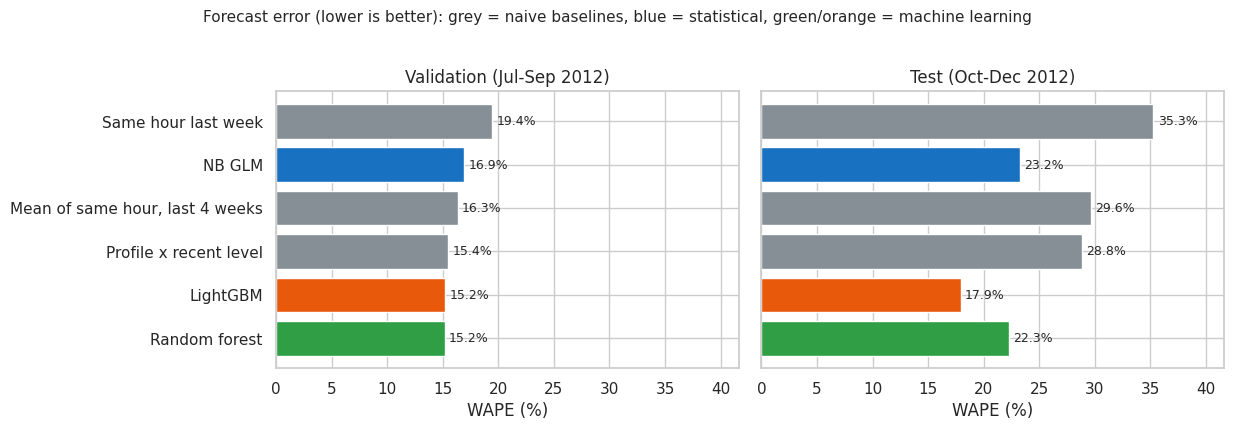

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
order = list(val_tbl.index)
for ax, (tbl, ttl) in zip(axes, [(val_tbl, "Validation (Jul-Sep 2012)"), (test_tbl.loc[order], "Test (Oct-Dec 2012)")]):
    cols = [GREY if k in BASE_NAMES else (BLUE if k == "NB GLM" else (GREEN if k == "Random forest" else ORANGE)) for k in tbl.index]
    b = ax.barh(tbl.index, tbl["wape"] * 100, color=cols); ax.invert_yaxis(); ax.set(title=ttl, xlabel="WAPE (%)")
    for rect, v in zip(b, tbl["wape"]): ax.text(v * 100 + .4, rect.get_y() + rect.get_height() / 2, f"{v:.1%}", va="center", fontsize=9)
    ax.set_xlim(0, max(val_tbl["wape"].max(), test_tbl["wape"].max()) * 100 * 1.18)
fig.suptitle("Forecast error (lower is better): grey = naive baselines, blue = statistical, green/orange = machine learning", y=1.02, fontsize=11)
save_fig(fig, "t6_10_model_comparison.png")

## 8. Interpretation and error analysis

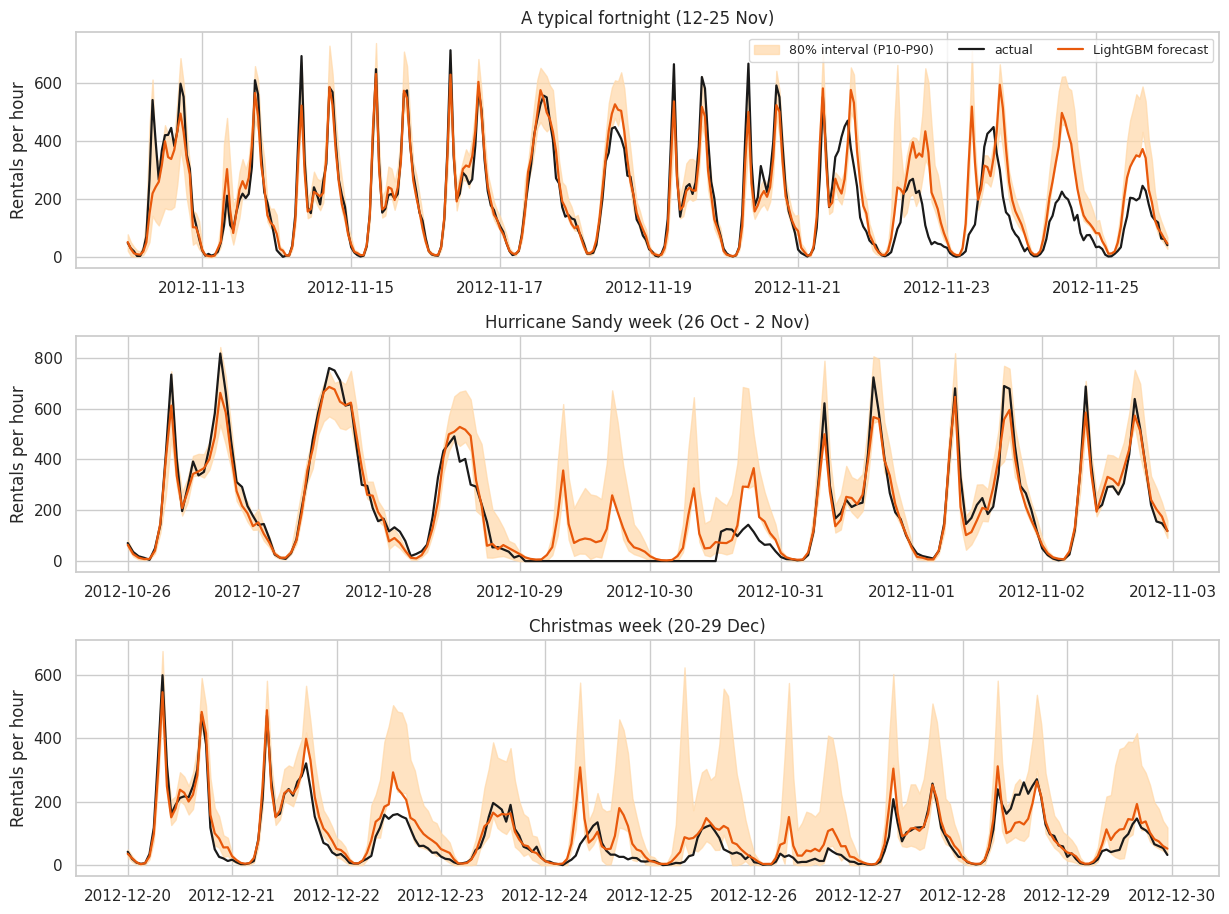

In [10]:
# forecasts vs actuals: a normal fortnight, the Hurricane Sandy week and Christmas week
# (quantile models are trained in section 9; fitted here first so the bands can be drawn)
taus = [0.1, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
qmodels = {t: fit_lgbm(X[trva], y[trva], objective="quantile", alpha=t, n_estimators=n_final, **best_cfg) for t in taus}
Q = pd.DataFrame({t: qmodels[t].predict(X[te]) for t in taus}, index=idx[te]); Q = pd.DataFrame(np.sort(Q.to_numpy(), axis=1), index=Q.index, columns=taus).clip(lower=0)   # non-crossing quantiles
pred = pd.DataFrame({"actual": yt, **{k: v for k, v in test_preds.items()}}, index=idx[te])
windows = [("2012-11-12", "2012-11-25", "A typical fortnight (12-25 Nov)"), ("2012-10-26", "2012-11-02", "Hurricane Sandy week (26 Oct - 2 Nov)"), ("2012-12-20", "2012-12-29", "Christmas week (20-29 Dec)")]
fig, axes = plt.subplots(3, 1, figsize=(12.5, 9.3))
for ax, (a, b, ttl) in zip(axes, windows):
    s = slice(a, b); ax.fill_between(Q.loc[s].index, Q.loc[s, 0.1], Q.loc[s, 0.9], color="#ffd8a8", alpha=.7, label="80% interval (P10-P90)")
    ax.plot(pred.loc[s].index, pred.loc[s, "actual"], color="k", lw=1.6, label="actual"); ax.plot(pred.loc[s].index, pred.loc[s, REC], color=ORANGE, lw=1.6, label=f"{REC} forecast"); ax.set(title=ttl, ylabel="Rentals per hour")
axes[0].legend(ncol=3, loc="upper right", fontsize=9); save_fig(fig, "t6_11_forecast_vs_actual.png")

The 5 event days are 5.4% of test hours but 7.8% of total absolute error (Sandy alone: 4.8%).
WAPE by month: {10: 0.158, 11: 0.201, 12: 0.186}


,wape,hours
sit,,
1,0.151,1226.0
2,0.178,786.0
3,0.571,196.0


,actual,LightGBM,err,note
ts,,,,
2012-11-23 08:00:00,94,517,423,
2012-10-02 18:00:00,687,302,-385,
2012-10-02 17:00:00,715,350,-365,
2012-10-19 18:00:00,233,596,363,
2012-10-29 08:00:00,0,357,357,Sandy
2012-10-02 08:00:00,134,459,325,
2012-11-22 17:00:00,109,432,323,
2012-11-12 08:00:00,540,219,-321,
2012-11-23 18:00:00,208,512,304,


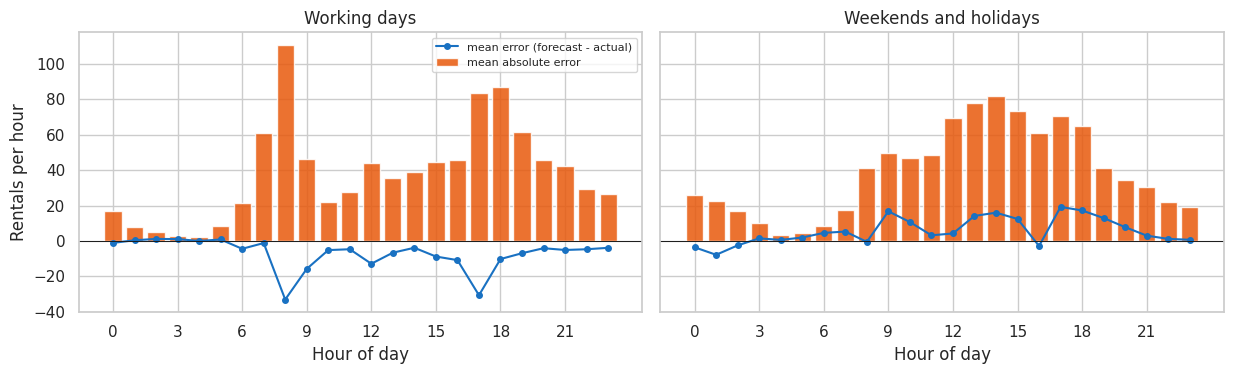

In [11]:
# where do the errors come from?
res = pred[["actual", REC]].assign(err=lambda t: t[REC] - t["actual"], abs_err=lambda t: (t[REC] - t["actual"]).abs(), hr=df.loc[te, "hr"].to_numpy(), wd=df.loc[te, "workingday"].to_numpy(),
                                          date=idx[te].normalize(), sit=df.loc[te, "weathersit"].to_numpy(), mnth=df.loc[te, "mnth"].to_numpy())
tot_err = res["abs_err"].sum(); ev_share = res.loc[res["date"].isin(EVENTS), "abs_err"].sum() / tot_err; sandy_share = res.loc[res["date"].isin(EVENTS[:2]), "abs_err"].sum() / tot_err
print(f"The 5 event days are {ev_t.mean():.1%} of test hours but {ev_share:.1%} of total absolute error (Sandy alone: {sandy_share:.1%}).")
R["event_error_share"], R["sandy_error_share"], R["event_hour_share"] = float(ev_share), float(sandy_share), float(ev_t.mean())
by_m = res.groupby("mnth").apply(lambda g: wape(g["actual"], g[REC]), include_groups=False).round(3); by_s = res.groupby("sit").apply(lambda g: pd.Series({"wape": wape(g["actual"], g[REC]), "hours": len(g)}), include_groups=False).round(3)
print("WAPE by month:", by_m.to_dict()); display(by_s)
R["wape_by_month"] = {int(k): float(v) for k, v in by_m.items()}; R["wape_by_weather"] = {int(k): {"wape": float(v["wape"]), "hours": int(v["hours"])} for k, v in by_s.iterrows()}
top = res.assign(miss=lambda t: t["err"]).reindex(res["abs_err"].sort_values(ascending=False).index).head(10)[["actual", REC, "err"]].round(0).astype(int); top["note"] = ["Sandy" if d in EVENTS[:2] else "Christmas week" if d in EVENTS[2:] else "" for d in top.index.normalize()]; display(top); R["top_misses"] = top.reset_index().astype({"ts": str}).to_dict("records")
hh = res.groupby(["wd", "hr"]).agg(mae=("abs_err", "mean"), bias=("err", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
for ax, wdv, ttl in zip(axes, [1, 0], ["Working days", "Weekends and holidays"]):
    h = hh[hh["wd"] == wdv]; ax.bar(h["hr"], h["mae"], color=ORANGE, alpha=.85, label="mean absolute error"); ax.plot(h["hr"], h["bias"], "o-", color=BLUE, ms=4, label="mean error (forecast - actual)"); ax.axhline(0, color="k", lw=.7); ax.set(title=ttl, xlabel="Hour of day", xticks=range(0, 24, 3))
axes[0].set_ylabel("Rentals per hour"); axes[0].legend(fontsize=8); save_fig(fig, "t6_12_error_by_hour.png")

Share of mean |SHAP| by feature group: {'calendar': 0.149, 'history': 0.707, 'weather': 0.144}
Top 10 features: {'same_hour_4w_mean': 0.939, 'temp_c': 0.096, 'hr': 0.073, 'lag_24': 0.061, 'lag_336': 0.057, 'hum_pct': 0.044, 'rain_last3h': 0.044, 'roll_28d_mean': 0.042, 'doy_cos': 0.041, 'lag_168': 0.039}


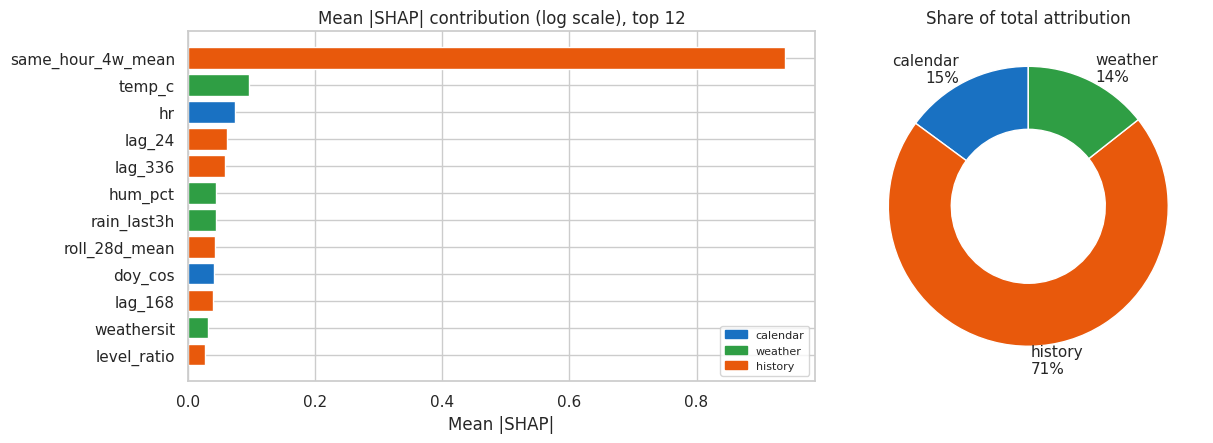

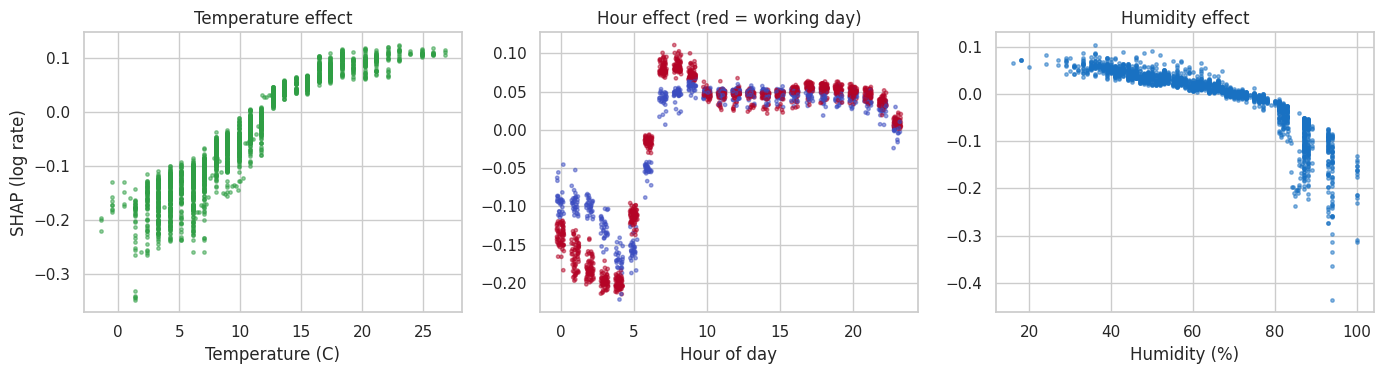

In [12]:
# --- TreeSHAP: why does the LightGBM model forecast what it does? (log-rate contributions) -------------------------
shap_df, base_val = tree_shap(lgbm_f, X[te])
imp = shap_df.abs().mean().sort_values(ascending=False); grp_of = {c: g for g, cols in groups.items() for c in cols}
grp_share = imp.groupby(imp.index.map(grp_of)).sum() / imp.sum(); print("Share of mean |SHAP| by feature group:", grp_share.round(3).to_dict()); print("Top 10 features:", imp.head(10).round(3).to_dict())
R["shap_top"] = imp.head(12).round(4).to_dict(); R["shap_groups"] = grp_share.round(4).to_dict()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
t12 = imp.head(12).iloc[::-1]; axes[0].barh(t12.index, t12.values, color=[{"calendar": BLUE, "weather": GREEN, "history": ORANGE}[grp_of[c]] for c in t12.index]); axes[0].set(title="Mean |SHAP| contribution (log scale), top 12", xlabel="Mean |SHAP|")
from matplotlib.patches import Patch; axes[0].legend(handles=[Patch(color=BLUE, label="calendar"), Patch(color=GREEN, label="weather"), Patch(color=ORANGE, label="history")], loc="lower right", fontsize=8)
axes[1].pie(grp_share.values, labels=[f"{k}\n{v:.0%}" for k, v in grp_share.items()], colors=[{"calendar": BLUE, "weather": GREEN, "history": ORANGE}[k] for k in grp_share.index], startangle=90, wedgeprops=dict(width=.45)); axes[1].set_title("Share of total attribution")
save_fig(fig, "t6_13_shap_importance.png")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].scatter(X.loc[te, "temp_c"], shap_df["temp_c"], s=6, alpha=.5, color=GREEN); axes[0].set(title="Temperature effect", xlabel="Temperature (C)", ylabel="SHAP (log rate)")
sc = axes[1].scatter(X.loc[te, "hr"] + np.random.default_rng(0).uniform(-.25, .25, te.sum()), shap_df["hr"], s=6, alpha=.5, c=X.loc[te, "workingday"], cmap="coolwarm"); axes[1].set(title="Hour effect (red = working day)", xlabel="Hour of day")
axes[2].scatter(X.loc[te, "hum_pct"], shap_df["hum_pct"], s=6, alpha=.5, color=BLUE); axes[2].set(title="Humidity effect", xlabel="Humidity (%)")
save_fig(fig, "t6_14_shap_dependence.png")

,rate_ratio,low,high
effect,,,
Mist / cloud vs clear,0.955,0.946,0.964
Rain / snow vs clear,0.584,0.575,0.594
Humidity +10 points,0.964,0.961,0.966
Wind +10 km/h,0.948,0.943,0.954
Public holiday,0.930,0.908,0.952
Level: +10% recent 28-day demand (elasticity),1.067,1.065,1.068
Memory: +10% same hour last week (elasticity),1.009,1.008,1.010


Temperature +5C effect at 5, 15, 25 C: {5: 1.18, 15: 1.055, 25: 0.944} | demand peaks near 22 C


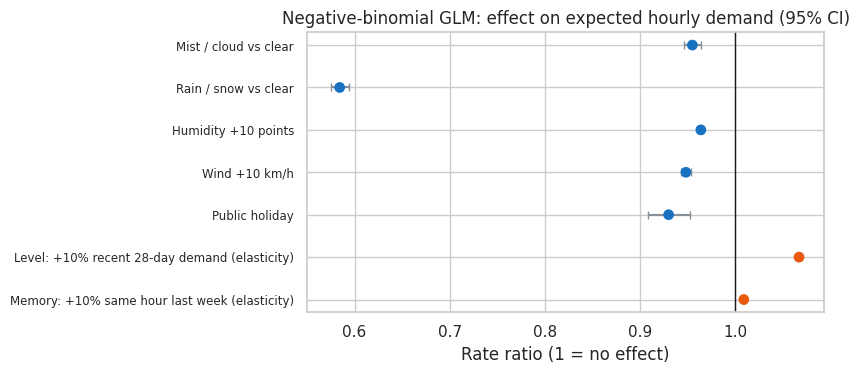

In [13]:
# --- NB GLM: effects as rate ratios (multiplicative changes in expected demand) -----------------------------------
p, ci = glm_f.params, glm_f.conf_int(); rr_rows = []
def add(label, name, scale=1.0):
    rr_rows.append({"effect": label, "rate_ratio": float(np.exp(p[name] * scale)), "low": float(np.exp(ci.loc[name, 0] * scale)), "high": float(np.exp(ci.loc[name, 1] * scale))})
add("Mist / cloud vs clear", "C(weathersit)[T.2]"); add("Rain / snow vs clear", "C(weathersit)[T.3]"); add("Humidity +10 points", "hum_pct", 10); add("Wind +10 km/h", "wind_kmh", 10); add("Public holiday", "holiday")
add("Level: +10% recent 28-day demand (elasticity)", "np.log1p(roll_28d_mean)", np.log(1.1)); add("Memory: +10% same hour last week (elasticity)", "np.log1p(lag_168)", np.log(1.1))
b1, b2 = p["temp_c"], p["I(temp_c ** 2)"]; temp_eff = {t: float(np.exp(5 * b1 + b2 * ((t + 5) ** 2 - t ** 2))) for t in (5, 15, 25)}
rr = pd.DataFrame(rr_rows).set_index("effect"); display(rr.round(3)); print("Temperature +5C effect at 5, 15, 25 C:", {k: round(v, 3) for k, v in temp_eff.items()}, f"| demand peaks near {-b1 / (2 * b2):.0f} C")
R["glm_temp_opt"] = float(-b1 / (2 * b2)); R["glm_rr"] = rr.round(4).to_dict("index"); R["glm_temp_effect"] = temp_eff; R["glm_alpha_final"] = float(alpha_f)
fig, ax = plt.subplots(figsize=(8.5, 3.9)); yy = np.arange(len(rr))[::-1]
ax.errorbar(rr["rate_ratio"], yy, xerr=[rr["rate_ratio"] - rr["low"], rr["high"] - rr["rate_ratio"]], fmt="none", ecolor=GREY, capsize=3); ax.scatter(rr["rate_ratio"], yy, c=[ORANGE if v > 1 else BLUE for v in rr["rate_ratio"]], s=45, zorder=3)
ax.axvline(1, color="k", lw=1); ax.set_yticks(yy); ax.set_yticklabels(rr.index, fontsize=8.5); ax.set(title="Negative-binomial GLM: effect on expected hourly demand (95% CI)", xlabel="Rate ratio (1 = no effect)")
save_fig(fig, "t6_15_glm_rate_ratios.png")

## 9. Robustness: what matters, and what could go wrong?
**Ablation** (validation quarter): how much does each feature group contribute? **Hour-ahead model**: what is real-time data worth? **Weather-forecast noise**: the models use observed weather as a stand-in for forecasts, so stress-test with noisy weather.

,wape,bias_pct
All features,0.1524,-0.0780
History + weather (no calendar),0.1526,-0.0416
Calendar + weather (no history),0.1769,-0.1453
Hour/day-type calendar + history (no weather),0.1836,-0.0521
History only,0.1913,-0.0430
Calendar only,0.2663,-0.2179
Calendar + history (no weather),0.3238,-0.2700


Hypothesis: year, month and season are confounded when only 18 months of data exist (summer 2012 was never seen), so calendar features without history under-forecast (negative bias).


LightGBM test WAPE: day-ahead 0.179 vs hour-ahead 0.124 (excluding event days: 0.166 vs 0.121)


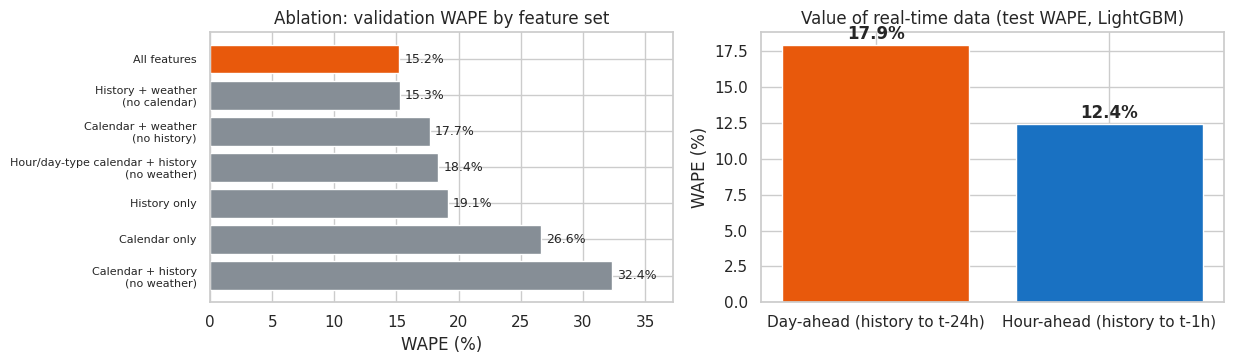

In [14]:
hour_cal = ["hr", "weekday", "workingday", "holiday", "is_weekend", "hour_sin", "hour_cos"]          # calendar WITHOUT year / month / season / day-of-year
variants = {"All features": sum(groups.values(), []), "Calendar + weather (no history)": groups["calendar"] + groups["weather"], "Calendar + history (no weather)": groups["calendar"] + groups["history"],
            "History + weather (no calendar)": groups["history"] + groups["weather"], "Calendar only": groups["calendar"], "History only": groups["history"],
            "Hour/day-type calendar + history (no weather)": hour_cal + groups["history"]}
abl = {}
for name, cols in variants.items():
    m = LGBMRegressor(objective="poisson", n_estimators=best_iter, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=1, **best_cfg).fit(X.loc[tr, cols], y[tr])
    pv = m.predict(X.loc[va, cols]); abl[name] = {"wape": wape(y[va], pv), "bias_pct": float((pv - y[va]).sum() / y[va].sum())}
abl_df = pd.DataFrame(abl).T.sort_values("wape"); display(abl_df.round(4)); R["ablation"] = abl_df.round(4).to_dict("index")
print("Hypothesis: year, month and season are confounded when only 18 months of data exist (summer 2012 was never seen), so calendar features without history under-forecast (negative bias).")
abl_s = abl_df["wape"]
# hour-ahead (nowcast) model: history up to one hour before the target
X1, _, g1 = build_features(df, horizon=1); u1 = X1["lag_168"].notna() & X1["roll_28d_mean"].notna(); tr1 = (idx < T_VAL) & u1; trva1 = tr1 | va; te1 = pd.Series(idx >= T_TEST, index=idx)
now = fit_lgbm(X1[trva1], y[trva1], objective="poisson", n_estimators=n_final, **best_cfg); p_now = now.predict(X1[te1])
R["nowcast_test_wape"] = float(wape(yt, p_now)); R["dayahead_test_wape_lgbm"] = float(wape(yt, test_preds["LightGBM"])); R["nowcast_test_wape_excl"] = float(wape(yt[~ev_t], p_now[~ev_t]))
print(f"LightGBM test WAPE: day-ahead {R['dayahead_test_wape_lgbm']:.3f} vs hour-ahead {R['nowcast_test_wape']:.3f} (excluding event days: {wape(yt[~ev_t], test_preds['LightGBM'][~ev_t]):.3f} vs {R['nowcast_test_wape_excl']:.3f})")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
a = abl_s.iloc[::-1]; axes[0].barh([k.replace(" (no", "\n(no") for k in a.index], a.values * 100, color=[ORANGE if k == "All features" else GREY for k in a.index]); axes[0].set(title="Ablation: validation WAPE by feature set", xlabel="WAPE (%)"); axes[0].tick_params(axis="y", labelsize=8)
for i, v in enumerate(a.values): axes[0].text(v * 100 + .4, i, f"{v:.1%}", va="center", fontsize=9)
axes[0].set_xlim(0, abl_s.max() * 100 * 1.15)
hv = {"Day-ahead (history to t-24h)": R["dayahead_test_wape_lgbm"], "Hour-ahead (history to t-1h)": R["nowcast_test_wape"]}; axes[1].bar(list(hv), [v * 100 for v in hv.values()], color=[ORANGE, BLUE]); axes[1].set(title="Value of real-time data (test WAPE, LightGBM)", ylabel="WAPE (%)")
for i, v in enumerate(hv.values()): axes[1].text(i, v * 100 + .4, f"{v:.1%}", ha="center", fontweight="bold")
save_fig(fig, "t6_16_ablation_nowcast.png")

In [15]:
# weather-forecast noise stress test: the champion was trained on observed weather; score it on perturbed weather (20 random draws)
champ_model = lgbm_f
def noisy_X(seed, sd_t=2.0, sd_h=8.0, sd_w=0.3, p_flip=0.15):
    r = np.random.default_rng(seed); d2 = df.copy(); m = (idx >= T_TEST); n = int(m.sum())
    d2.loc[m, "temp_c"] = d2.loc[m, "temp_c"] + r.normal(0, sd_t, n); d2.loc[m, "hum_pct"] = np.clip(d2.loc[m, "hum_pct"] + r.normal(0, sd_h, n), 10, 100)
    d2.loc[m, "wind_kmh"] = d2.loc[m, "wind_kmh"] * np.exp(r.normal(0, sd_w, n)); shift = np.where(r.random(n) < p_flip, r.choice([-1, 1], n), 0); d2.loc[m, "weathersit"] = np.clip(d2.loc[m, "weathersit"].to_numpy() + shift, 1, 3)
    return build_features(d2, 24)[0]
noisy = [wape(yt, champ_model.predict(noisy_X(s).loc[te])) for s in range(20)]; clean_w = wape(yt, champ_model.predict(X[te]))
R["noise"] = {"clean": float(clean_w), "mean": float(np.mean(noisy)), "sd": float(np.std(noisy)), "worst": float(np.max(noisy))}
print(f"Test WAPE with observed weather {clean_w:.3f}; with noisy weather (temp +/-2C, humidity +/-8 pts, wind +/-30%, 15% of hours mis-classified): {np.mean(noisy):.3f} +/- {np.std(noisy):.3f} (worst {np.max(noisy):.3f})")
# sensitivity of the main conclusion to the "absent hour = zero demand" assumption
keep = (df["missing_hour"] == 0).to_numpy()[te.to_numpy()]; R["wape_excl_absent_hours"] = float(wape(yt[keep], rec_p[keep])); R["wape_with_absent_hours"] = float(rec_w)
print(f"{REC} test WAPE: {rec_w:.3f} including the {int((~keep).sum())} absent (zero-demand) hours vs {R['wape_excl_absent_hours']:.3f} if they are dropped")

Test WAPE with observed weather 0.179; with noisy weather (temp +/-2C, humidity +/-8 pts, wind +/-30%, 15% of hours mis-classified): 0.201 +/- 0.002 (worst 0.207)
LightGBM test WAPE: 0.179 including the 40 absent (zero-demand) hours vs 0.173 if they are dropped


## 10. Prediction intervals and operational planning

Share of test hours with actual <= predicted quantile: {0.1: 0.179, 0.5: 0.442, 0.6: 0.526, 0.7: 0.618, 0.8: 0.749, 0.9: 0.862, 0.95: 0.915}
Nominal 80% interval (P10-P90): coverage 68.8%, mean width 105 rentals | excluding event days: 69.9%


Validation coverage of the raw interval: 67.4%; conformal adjustment = +12.1 rentals each side
Test coverage after recalibration: 81.4% (width 128); excluding event days 82.5%


segment,all hours,off-peak,peak hours
planning_quantile,,,
0.50,0.558,0.561,0.544
0.60,0.474,0.472,0.482
0.70,0.382,0.374,0.412
0.80,0.251,0.238,0.302
0.90,0.138,0.130,0.171
0.95,0.085,0.078,0.113


segment,all hours,off-peak,peak hours
planning_quantile,,,
0.50,0.106,0.113,0.097
0.60,0.132,0.145,0.114
0.70,0.170,0.190,0.141
0.80,0.231,0.266,0.181
0.90,0.320,0.382,0.231
0.95,0.400,0.485,0.277


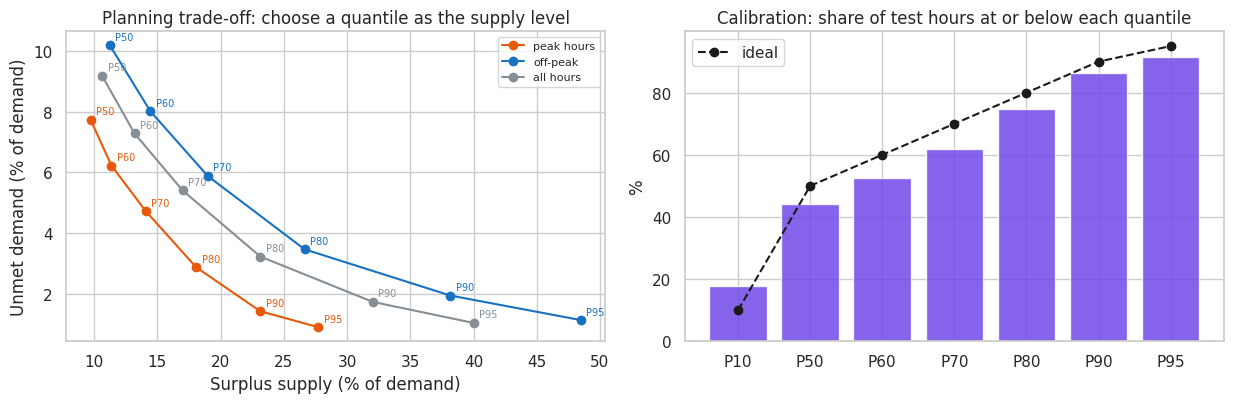

In [16]:
# empirical coverage of the quantile forecasts on the TEST period
cov_q = {t: float((yt <= Q[t].to_numpy()).mean()) for t in taus}; R["quantile_coverage"] = cov_q; print("Share of test hours with actual <= predicted quantile:", {t: round(v, 3) for t, v in cov_q.items()})
iv = interval_report(yt, Q[0.1].to_numpy(), Q[0.9].to_numpy()); iv_ex = interval_report(yt[~ev_t], Q[0.1].to_numpy()[~ev_t], Q[0.9].to_numpy()[~ev_t])
R["interval80"], R["interval80_excl_events"] = iv, iv_ex; print(f"Nominal 80% interval (P10-P90): coverage {iv['coverage']:.1%}, mean width {iv['mean_width']:.0f} rentals | excluding event days: {iv_ex['coverage']:.1%}")
R["pinball"] = {str(t): float(pinball_loss(yt, Q[t].to_numpy(), t)) for t in taus}
# conformalised quantile regression (CQR): widen/shrink the interval by a constant learned on the VALIDATION quarter (models trained on train only)
ql = fit_lgbm(X[tr], y[tr], objective="quantile", alpha=0.1, n_estimators=best_iter, **best_cfg); qh = fit_lgbm(X[tr], y[tr], objective="quantile", alpha=0.9, n_estimators=best_iter, **best_cfg)
lo_v, hi_v = np.minimum(ql.predict(X[va]), qh.predict(X[va])), np.maximum(ql.predict(X[va]), qh.predict(X[va])); yv = y[va].to_numpy()
iv_val = interval_report(yv, lo_v, hi_v); score = np.maximum(lo_v - yv, yv - hi_v); n_c = len(score)
qhat = float(np.quantile(score, min(1.0, np.ceil((n_c + 1) * 0.8) / n_c), method="higher"))
lo_c, hi_c = np.clip(Q[0.1].to_numpy() - qhat, 0, None), Q[0.9].to_numpy() + qhat; iv_cqr = interval_report(yt, lo_c, hi_c); iv_cqr_ex = interval_report(yt[~ev_t], lo_c[~ev_t], hi_c[~ev_t])
print(f"Validation coverage of the raw interval: {iv_val['coverage']:.1%}; conformal adjustment = {qhat:+.1f} rentals each side")
print(f"Test coverage after recalibration: {iv_cqr['coverage']:.1%} (width {iv_cqr['mean_width']:.0f}); excluding event days {iv_cqr_ex['coverage']:.1%}")
R["interval80_val_raw"], R["cqr_qhat"], R["interval80_cqr"], R["interval80_cqr_excl_events"] = iv_val, qhat, iv_cqr, iv_cqr_ex
plan_rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    for seg, mk in [("all hours", np.ones(len(yt), bool)), ("peak hours", pk_t), ("off-peak", ~pk_t)]:
        r_ = planning_tradeoff(yt[mk], Q[t].to_numpy()[mk]); plan_rows.append({"planning_quantile": t, "segment": seg, **r_})
plan = pd.DataFrame(plan_rows); display(plan.pivot(index="planning_quantile", columns="segment", values="shortage_rate").round(3)); display(plan.pivot(index="planning_quantile", columns="segment", values="surplus_share").round(3))
R["planning"] = plan.round(4).to_dict("records"); plan.round(4).to_csv(TAB / "planning_tradeoff.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for seg, col in [("peak hours", ORANGE), ("off-peak", BLUE), ("all hours", GREY)]:
    s_ = plan[plan["segment"] == seg]; axes[0].plot(s_["surplus_share"] * 100, s_["unmet_share"] * 100, "o-", color=col, label=seg)
    for _, r_ in s_.iterrows(): axes[0].annotate(f"P{int(r_['planning_quantile'] * 100)}", (r_["surplus_share"] * 100, r_["unmet_share"] * 100), textcoords="offset points", xytext=(4, 4), fontsize=7, color=col)
axes[0].set(title="Planning trade-off: choose a quantile as the supply level", xlabel="Surplus supply (% of demand)", ylabel="Unmet demand (% of demand)"); axes[0].legend(fontsize=8)
axes[1].bar([f"P{int(t * 100)}" for t in taus], [cov_q[t] * 100 for t in taus], color=PURPLE, alpha=.85); axes[1].plot(range(len(taus)), [t * 100 for t in taus], "k--", marker="o", label="ideal"); axes[1].set(title="Calibration: share of test hours at or below each quantile", ylabel="%"); axes[1].legend()
save_fig(fig, "t6_17_planning_and_calibration.png")

## 11. Success criteria, persistence and conclusions

In [17]:
import os, re
pt = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=ROOT, env={**os.environ, "PYTHONPATH": str(ROOT / "src")}, capture_output=True, text=True)
mt = re.search(r"(\d+) passed", pt.stdout); tests_ok = pt.returncode == 0 and mt is not None; n_tests = int(mt.group(1)) if tests_ok else 0
crit = {"S1: WAPE at least 25% lower than the best naive baseline": (R["relative_improvement_champion"] >= 0.25, R["relative_improvement_rec"] >= 0.25),
        "S2: test WAPE <= 25%": (champ_w <= 0.25, rec_w <= 0.25),
        "S3: 80% interval coverage between 70% and 90% (raw quantile models)": (None, 0.70 <= iv["coverage"] <= 0.90),
        "S3b: same after conformal recalibration (validation-calibrated)": (None, 0.70 <= iv_cqr["coverage"] <= 0.90),
        "S4: all unit tests pass": (tests_ok, tests_ok)}
print(f"{'criterion':<72}{'declared champion (' + champion + ')':<30}{REC + ' (chosen after seeing test)'}")
for k, (a, b) in crit.items(): print(f"{k:<72}{('n/a' if a is None else ('MET' if a else 'NOT MET')):<30}{'MET' if b else 'NOT MET'}")
R["criteria"] = {k: {"declared_champion": (None if a is None else bool(a)), "recommended": bool(b)} for k, (a, b) in crit.items()}; R["n_tests"] = n_tests
print(f"details: improvement over baseline {R['relative_improvement_champion']:.1%} ({champion}) / {R['relative_improvement_rec']:.1%} ({REC}); WAPE {champ_w:.1%} / {rec_w:.1%}; interval coverage {iv['coverage']:.1%} raw, {iv_cqr['coverage']:.1%} recalibrated; {n_tests} tests")
# persist models and predictions
joblib.dump({"model": lgbm_f, "features": list(X.columns), "n_trees": n_final, "cfg": best_cfg, "trained_through": str(idx[trva].max())}, MOD / "lgbm_day_ahead.joblib")
joblib.dump({"quantiles": {t: qmodels[t] for t in taus}, "features": list(X.columns)}, MOD / "lgbm_quantiles.joblib")
glm_f.params.to_csv(TAB / "nb_glm_coefficients.csv"); pred.join(Q.add_prefix("q")).round(2).to_csv(TAB / "test_predictions.csv")
rl = joblib.load(MOD / "lgbm_day_ahead.joblib"); must(np.allclose(rl["model"].predict(X[te]), test_preds["LightGBM"]), "reloaded model reproduces test forecasts exactly")
(ROOT / "outputs" / "model_metrics.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))); print("saved model_metrics.json")

criterion                                                               declared champion (Random forest)LightGBM (chosen after seeing test)
S1: WAPE at least 25% lower than the best naive baseline                NOT MET                       MET
S2: test WAPE <= 25%                                                    MET                           MET
S3: 80% interval coverage between 70% and 90% (raw quantile models)     n/a                           NOT MET
S3b: same after conformal recalibration (validation-calibrated)         n/a                           MET
S4: all unit tests pass                                                 MET                           MET
details: improvement over baseline 22.7% (Random forest) / 37.8% (LightGBM); WAPE 22.3% / 17.9%; interval coverage 68.8% raw, 81.4% recalibrated; 22 tests


[OK] reloaded model reproduces test forecasts exactly
saved model_metrics.json


## 12. Results, interpretation and conclusions

### Model selection: what happened, stated plainly
- The **pre-declared rule** (lowest validation WAPE) selected the **random forest** (0.1516) over LightGBM (0.1524): a statistical tie. I had not declared a tie-break rule.
- On the held-out test quarter LightGBM was clearly better (WAPE 17.9% vs 22.3%) and the Diebold-Mariano test confirms it beats every other model (all p < 0.001).
- I therefore analyse **LightGBM** in sections 8-10, but flag that this choice used test information, so its test numbers are mildly optimistic. Criteria are reported for both models.

### Main results (test quarter, Oct-Dec 2012)
| Model | WAPE | WAPE excl. event days | Bias |
|---|---|---|---|
| LightGBM (recommended) | 17.9% | 16.6% | -1.4% |
| Random forest (pre-declared champion) | 22.3% | 19.6% | +9.2% |
| NB GLM | 23.2% | 20.8% | -1.5% |
| Profile x recent level (best baseline) | 28.8% | 23.8% | +14.0% |
| Same hour last week | 35.3% | 29.9% | +8.5% |

LightGBM is **37.8% better** than the best naive baseline. In peak commuting hours its WAPE is 15.9%.

### Findings
1. **ML advantage depends on the regime.** In the stable summer validation quarter a profile-times-recent-level baseline (15.4%) was within 2% of the ML models (15.2%). In the autumn test quarter the baseline fell to 28.8% because demand was declining seasonally and a 28-day level lags behind (bias +14%). Learned weather and history features adapt better.
2. **Demand is mostly persistence plus weather.** History features carry 71% of the model's attribution, weather 14% and calendar 15%. In the GLM, rain or snow cuts expected demand by about 42%, +10 humidity points by 3.6%, +10 km/h wind by 5.2%, a public holiday by 7%, and demand peaks near 22 C.
3. **Calendar features can mislead with under two years of data.** Year, month and season are confounded with growth: a calendar-plus-history model without weather had a bias of -27% on validation. Using only hour/day-type calendar features cut its WAPE from 0.324 to 0.184. This hypothesis was tested on validation data; adopting it would need re-validation.
4. **Real-time data is valuable.** An hour-ahead model reaches 12.4% WAPE against 17.9% day-ahead (31% lower error).
5. **Uncertainty.** The raw P10-P90 interval covered only 68.8% of test hours (nominal 80%). Conformal recalibration using the validation quarter lifts coverage to 81.4% at the cost of 22% wider intervals.
6. **Robustness.** Corrupting the weather inputs (to mimic forecast error) raises WAPE from 17.9% to about 20.1%, still better than every baseline. Treating absent hours as zero demand changes WAPE by only 0.6 points.
7. **Where it fails.** Hurricane Sandy (29-30 Oct), Christmas week, the day after Thanksgiving (a working day by the calendar but a de-facto holiday: 94 rentals at 8 a.m. versus 551 the day before) and rain-affected hours (WAPE 57% vs 15% in clear weather). The 5 event days are 5.4% of test hours but 7.8% of absolute error.

### Success criteria
| Criterion | Pre-declared champion (random forest) | LightGBM (chosen after seeing test) |
|---|---|---|
| S1: WAPE >= 25% lower than best baseline | **Not met** (22.7%) | Met (37.8%) |
| S2: test WAPE <= 25% | Met (22.3%) | Met (17.9%) |
| S3: 80% interval coverage within 70-90% | n/a | **Not met** raw (68.8%); met after recalibration (81.4%) |
| S4: all unit tests pass | Met (22 tests) | Met |

### Limitations
One city and 2 years; system-level (not station-level) totals; weather is observed rather than forecast (stress-tested only with synthetic noise); observed rentals understate true demand when bikes or docks run out; a 3-month test window with unusual events; growth makes the problem non-stationary.